**API Data Report**

Weiss-Vopat, Emerson

October 20, 2026

**Hypothesis:** Shorter length Bluesky posts about horror media receive more likes than longer length posts about horror media.

My hypothesis presupposes that posts with more information (longer posts) are generally going to be less popular (less likes) than posts that are less content heavy. In order to do this, I will compare the length of posts with the number of likes of a certain amount of posts (containing keyword: "horror").

**Primary Variables:** Length of posts and number of likes

**Primary API Endpoints:** 

* app.bsky.feed.getProfile - used to search for posts with the keyword "horror," as well as the number of likes.
* app.bsky.feed.searchPosts - used to get a general idea of whether or not posts with higher like counts were often from accounts with higher follower counts.

**Reliability:** The data used is not entirely reliable as Bluesky is obviously not stagnant, and the amount of followers/likes/posts are constantly changing. I also have a limited source of posts, as well as a limited source of posts that are horror media, since I am only using one keyword.

**Conclusions:** Generally from my data, I cannot concretely say that follower count makes a difference in the amount of likes, as well as cannot prove my hypothesis that shorter length posts about horror media receive more likes than longer ones. Within my sample size, my conclusions show that longer posts may receive more likes, but it is far too weak of a relationship to say for certain. In the future, I should search using more keywords, as well as analyzing further portions of the variables I was using so I could better understand the data I was using.

**Sources:** Lines 5 and 7 were assisted with two videos, one of which account I have lost since I watched while logged out, the other (and primary) being https://www.youtube.com/@cameronmcnz

In [309]:
import requests
import pandas as pd

In [310]:
url = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"

params = {
    "q": "horror",
    "limit": 100
}

response = requests.get(url, params=params, timeout=10)

print(response.status_code)

200


In [311]:
data = response.json()
posts = data["posts"]
print(len(posts))

99


In [312]:
posts_df = pd.DataFrame([
    {
        "text": post["record"]["text"],
        "post_length": len(post["record"]["text"]),
        "likes": post["likeCount"],
        "reposts": post["repostCount"],
        "replies": post["replyCount"],
        "author_did": post["author"]["did"]
    }
    for post in posts
])

posts_df.head()

,text,post_length,likes,reposts,replies,author_did
0,"Full description: After the Mets lose Game 6, ...",286,0,0,0,did:plc:thp7y3txmqt72etmusfm3hfg
1,passende hose finden einfach der horror,39,0,0,0,did:plc:hqwbomyeupub3fuo652pfi6j
2,"Oct 21-27 – Swift & Winehouse, Kang & Kodos an...",143,0,0,1,did:plc:thp7y3txmqt72etmusfm3hfg
3,"seriously, give me a throwback survival horror...",266,0,0,0,did:plc:3zdregbvl37e4svqfbcdmq2f
4,wow this is stupid. regional horror is always ...,78,0,0,0,did:plc:kl5azwmax5cczlexygooonc6


In [313]:
profile_url = "https://api.bsky.app/xrpc/app.bsky.actor.getProfile"

profiles = []

for actor in posts_df["author_did"].drop_duplicates().head(10): params = {"actor": actor}
response = requests.get(profile_url, params=params, timeout=10)

if response.status_code == 200:
    profile = response.json()
    profiles.append({
        "author_did": profile["did"],
        "followers": profile.get("followersCount")
    })

profiles_df = pd.DataFrame(profiles)
profiles_df.head()

,author_did,followers
0,did:plc:72xjk7r365xvyxliue75qsdk,3337


In [314]:
final_df = pd.merge(
    posts_df,
    profiles_df,
    on="author_did",
    how="left"
)

final_df.head()

,text,post_length,likes,reposts,replies,author_did,followers
0,"Full description: After the Mets lose Game 6, ...",286,0,0,0,did:plc:thp7y3txmqt72etmusfm3hfg,NaN
1,passende hose finden einfach der horror,39,0,0,0,did:plc:hqwbomyeupub3fuo652pfi6j,NaN
2,"Oct 21-27 – Swift & Winehouse, Kang & Kodos an...",143,0,0,1,did:plc:thp7y3txmqt72etmusfm3hfg,NaN
3,"seriously, give me a throwback survival horror...",266,0,0,0,did:plc:3zdregbvl37e4svqfbcdmq2f,NaN
4,wow this is stupid. regional horror is always ...,78,0,0,0,did:plc:kl5azwmax5cczlexygooonc6,NaN


In [315]:
final_df["post_length"].corr(final_df["likes"])

np.float64(0.07558051448480639)

Regardless of refresh [and negative/positive], correlation value stays in decimal ranges. never reaching -1 or 1.

In [316]:
import matplotlib.pyplot as plt

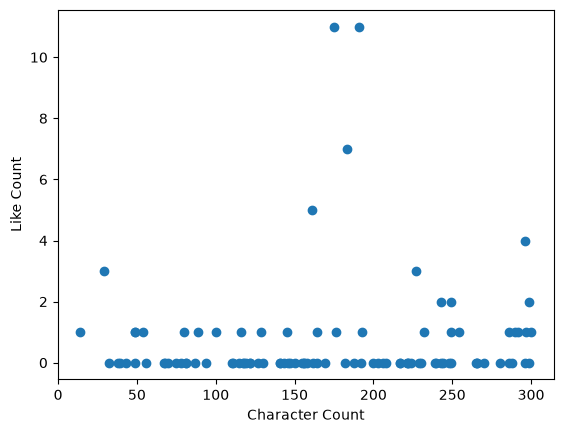

In [317]:
plt.scatter(final_df["post_length"], final_df["likes"])
plt.xlabel("Character Count")
plt.ylabel("Like Count")

plt.show()

Graph shows a weak relationship between character count and like count.